# LLM Reservoir Operators: F.E. Walter Tutorial

Compare rule-based and LLM operations across 2021 at **F.E. Walter Dam** (PA).

| Part | Focus |
| --- | --- |
| 1–2 | [HydroCNHS](https://github.com/philip928lin/HydroCNHS) link, dam specs, 3 policies |
| 3–4 | 2021 Fig. 3 replay & offline Rule-based run |
| 5–6 | LLM prompts/guards & Hanasaki + LLM cascade |
| 7 | Optional live Ollama (2021) |

> Use `.venv` (Python 3.12); open from repo root or `tutorials/`.

## 1. Architecture & HydroCNHS Coupling

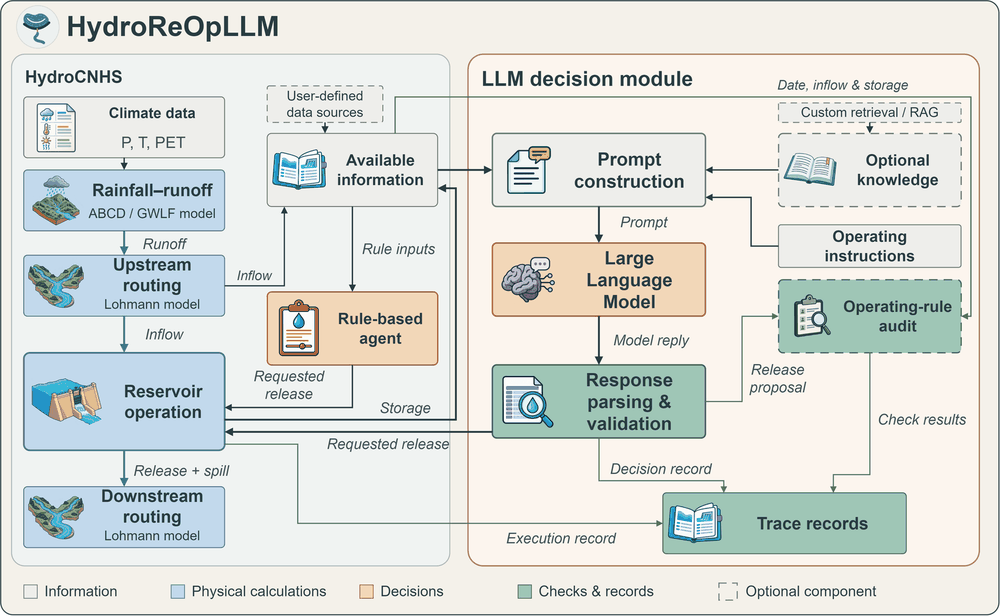

| Layer | Role |
| --- | --- |
| Hydrology | [HydroCNHS](https://github.com/philip928lin/HydroCNHS) runoff/routing ([guide](../docs/HYDROLOGY_SETUP.md)); tutorial uses prepared `inflows.csv` |
| Operator | Rule-based or LLM agent chooses daily release |
| Physics & Audit | Enforces bounds, computes spill, logs water balance |

## 2. Study Area & Benchmark Conditions

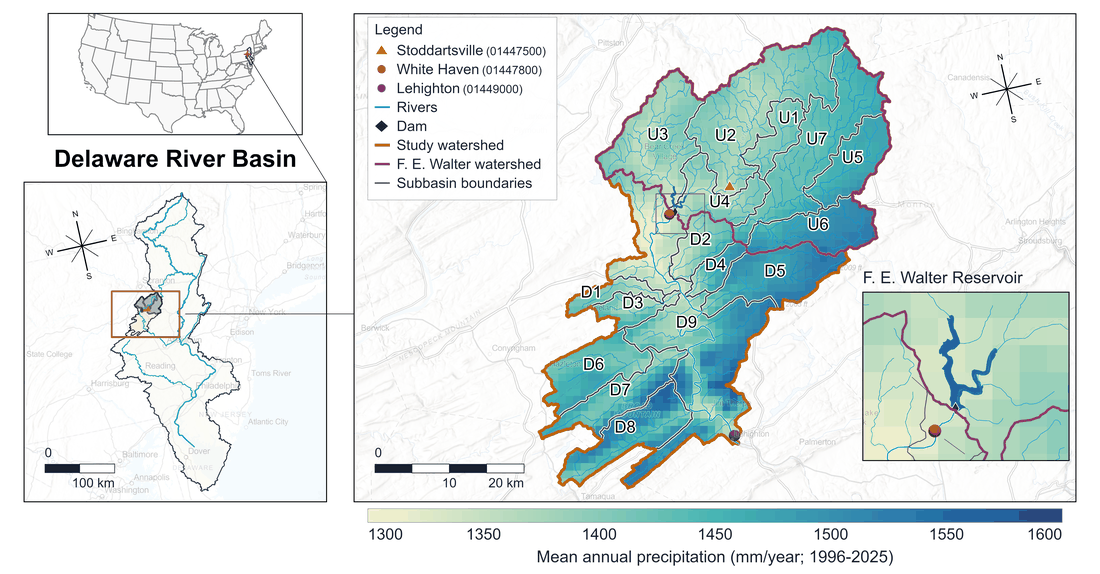

**F.E. Walter Dam:** $289\text{ mi}^2$, $135.53\text{M m}^3$, $50\text{–}10{,}000\text{ cfs}$, pool target `1,300 ↔ 1,370 ft` (`01447800` / `01449000`).

| Condition | YAML | Policy | Calls/day |
| --- | --- | --- | --- |
| Rule-based | `rule_based.yaml` | Hanasaki flood-control rule ($\alpha=0.85$) | `0` |
| Without operational knowledge | `seasonal_target.yaml` | `gemma4:12b` + seasonal target | `1` |
| With operational knowledge | `dkp.yaml` | `gemma4:12b` + `dkp.md` rules | `1` |

## 3. 2021 Replay Comparison (Paper Figure 3)

Offline 365-day (`2021-01-01`–`2021-12-31`, 10-seed median) replay in Paper Fig. 3 format ([study guide](../examples/fe_walter/README.md)).

In [1]:
import csv
import hashlib
import math
from datetime import date
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd

from llm_reservoir_agent.case import RecordedResponseBackend, load_case
from llm_reservoir_agent.network import run_network
from llm_reservoir_agent.rule_based import no_model_transport
from llm_reservoir_agent.workflow import load_settings

CFS_TO_CMS = 0.028316847
ACFT_TO_M3 = 1233.48183754752

repo_root = Path.cwd().parent if Path.cwd().name == "tutorials" else Path.cwd()
study_dir = repo_root / "examples" / "fe_walter"

curve_df = pd.read_csv(study_dir / "study" / "elevation_storage.csv")
curve_volume_m3 = curve_df["storage_acft"].to_numpy() * ACFT_TO_M3
curve_level_ft = curve_df["elevation_ft_ngvd29"].to_numpy()

obs_2021 = pd.read_csv(study_dir / "study" / "observations.csv", parse_dates=["date"])
obs_2021 = obs_2021[(obs_2021["date"] >= "2021-01-01") & (obs_2021["date"] <= "2021-12-31")].reset_index(drop=True)


def storage_to_elevation_ft(storage_m3):
    return np.interp(storage_m3, curve_volume_m3, curve_level_ft)


def target_elevation_ft(dates):
    values = []
    for ts in pd.to_datetime(dates):
        d = ts.date()
        apr1, may15 = date(d.year, 4, 1), date(d.year, 5, 15)
        oct1, oct15 = date(d.year, 10, 1), date(d.year, 10, 15)
        if d <= apr1 or d >= oct15:
            values.append(1300.0)
        elif d < may15:
            values.append(1300.0 + 70.0 * (d - apr1).days / (may15 - apr1).days)
        elif d <= oct1:
            values.append(1370.0)
        else:
            values.append(1370.0 - 70.0 * (d - oct1).days / (oct15 - oct1).days)
    return np.asarray(values, dtype=float)


def score_series(simulated, observed):
    sim = np.asarray(simulated, dtype=float)
    obs = np.asarray(observed, dtype=float)
    mean_s, mean_o = float(sim.mean()), float(obs.mean())
    std_s, std_o = float(sim.std()), float(obs.std())
    corr = float(np.corrcoef(sim, obs)[0, 1]) if std_s > 0 and std_o > 0 else 0.0
    kge = 1.0 - math.sqrt((corr - 1.0) ** 2 + ((std_s / std_o) - 1.0) ** 2 + ((mean_s / mean_o) - 1.0) ** 2)
    rmse = float(np.sqrt(np.mean((sim - obs) ** 2)))
    return {"kge": kge, "rmse": rmse}


releases_file = study_dir / "study" / "archived_releases.csv"
releases_sha256 = hashlib.sha256(releases_file.read_bytes()).hexdigest()
archived_2021 = {}
with releases_file.open(newline="", encoding="utf-8") as stream:
    for row in csv.DictReader(stream):
        if "2021-01-01" <= row["date"] <= "2021-12-31":
            archived_2021.setdefault((row["condition"], int(row["seed"])), []).append(
                {"date": row["date"], "release_cms": float(row["release_cms"])}
            )

llm_network, llm_inflows = load_case(study_dir / "case.json", project_root=study_dir)
llm_rows_2021 = [row for row in llm_inflows if "2021-01-01" <= row["date"] <= "2021-12-31"]

rule_settings = load_settings(study_dir / "rule_based.yaml", runtime_root=repo_root)
rule_spec = rule_settings.agents["walter_operator"]
rule_network, rule_inflows = load_case(study_dir / "rule_case.json", project_root=study_dir)
rule_rows_2021 = [row for row in rule_inflows if "2021-01-01" <= row["date"] <= "2021-12-31"]
rule_backend = rule_spec["extension_runtime"].build_backend(
    rule_spec,
    physical=rule_network["reservoirs"]["FEWalter"]["physical"],
    runtime_root=repo_root,
    mode="offline",
    model=None,
    transport=no_model_transport,
)


def records_to_df(records):
    return pd.DataFrame([
        {
            "date": pd.Timestamp(item["observation"]["timestamp"][:10]),
            "inflow_cms": item["observation"]["inflow_cms"],
            "controlled_release_cms": item["transition"]["controlled_release_cms"],
            "total_outflow_cms": item["transition"]["total_outflow_cms"],
            "storage_end_m3": item["transition"]["storage_end_m3"],
        }
        for item in records["FEWalter"]
    ])


rule_records, _ = run_network(rule_network, rule_rows_2021, {"FEWalter": rule_backend}, project_root=repo_root)
rule_df_2021 = records_to_df(rule_records)

reference_cases = {
    "Rule-based": ("rule", 0),
    "Without operational knowledge": ("without", 365),
    "With operational knowledge": ("with", 365),
}
reference_runs = {"Rule-based": {"trajectory": rule_df_2021}}
reference_metrics = [
    {
        "Case": "Rule-based",
        "Seeds": "1 (deterministic)",
        "Elev KGE": score_series(storage_to_elevation_ft(rule_df_2021["storage_end_m3"]), obs_2021["water_level_ft"])["kge"],
        "Elev RMSE (ft)": score_series(storage_to_elevation_ft(rule_df_2021["storage_end_m3"]), obs_2021["water_level_ft"])["rmse"],
        "Release KGE": score_series(rule_df_2021["total_outflow_cms"] / CFS_TO_CMS, obs_2021["release_cfs"])["kge"],
        "Release RMSE (ft³/s)": score_series(rule_df_2021["total_outflow_cms"] / CFS_TO_CMS, obs_2021["release_cfs"])["rmse"],
        "Requests/seed": 0,
    }
]

for label, cond in [("Without operational knowledge", "without_knowledge"), ("With operational knowledge", "with_knowledge")]:
    seed_dfs = []
    elev_scores, rel_scores = [], []
    for seed in range(1, 11):
        backend = RecordedResponseBackend(
            archived_2021[(cond, seed)], data_kind="recorded_llm_response", source_sha256=releases_sha256
        )
        rec, _ = run_network(llm_network, llm_rows_2021, {"FEWalter": backend}, project_root=repo_root)
        df_s = records_to_df(rec)
        seed_dfs.append(df_s)
        elev_scores.append(score_series(storage_to_elevation_ft(df_s["storage_end_m3"]), obs_2021["water_level_ft"]))
        rel_scores.append(score_series(df_s["total_outflow_cms"] / CFS_TO_CMS, obs_2021["release_cfs"]))

    median_df = seed_dfs[0][["date", "inflow_cms"]].copy()
    for col in ("controlled_release_cms", "total_outflow_cms", "storage_end_m3"):
        median_df[col] = np.median(np.column_stack([d[col].to_numpy() for d in seed_dfs]), axis=1)
    reference_runs[label] = {"trajectory": median_df, "seed_trajectories": seed_dfs}
    reference_metrics.append({
        "Case": label,
        "Seeds": "1–10 (median)",
        "Elev KGE": float(np.median([s["kge"] for s in elev_scores])),
        "Elev RMSE (ft)": float(np.median([s["rmse"] for s in elev_scores])),
        "Release KGE": float(np.median([s["kge"] for s in rel_scores])),
        "Release RMSE (ft³/s)": float(np.median([s["rmse"] for s in rel_scores])),
        "Requests/seed": 365,
    })

pd.DataFrame(reference_metrics).set_index("Case").round(3)

,Seeds,Elev KGE,Elev RMSE (ft),Release KGE,Release RMSE (ft³/s),Requests/seed
Case,,,,,,
Rule-based,1 (deterministic),0.193,79.027,0.478,896.436,0
Without operational knowledge,1–10 (median),0.852,18.016,0.696,748.139,365
With operational knowledge,1–10 (median),0.873,16.458,0.616,914.551,365


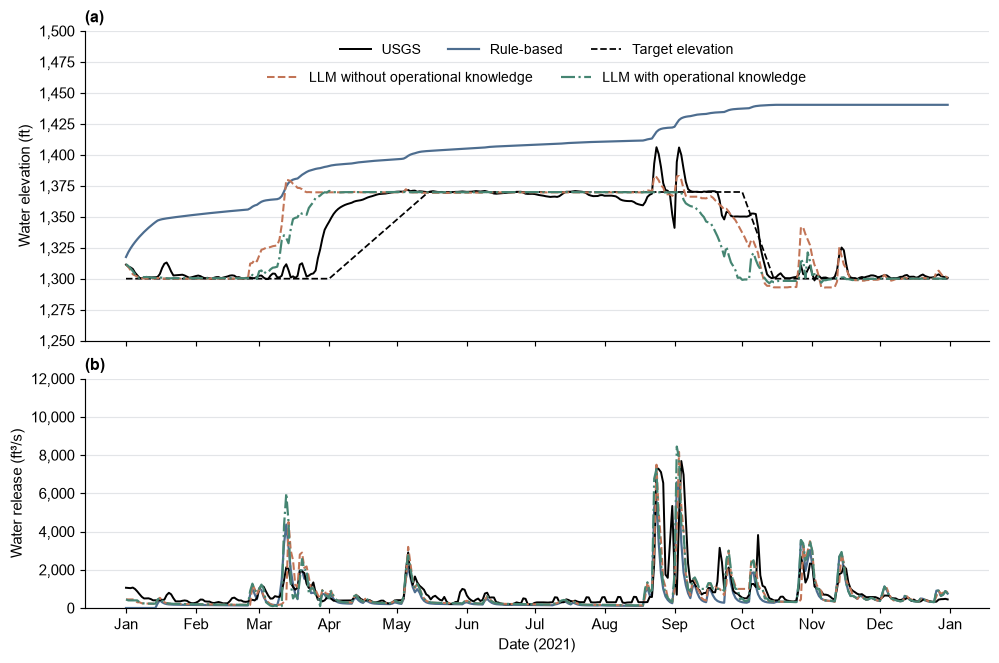

In [2]:
def plot_figure3_2021(runs):
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = ["Arial", "DejaVu Sans"]

    figure, (ax_elev, ax_rel) = plt.subplots(
        2, 1,
        sharex=True,
        figsize=(9.4, 6.2),
        dpi=105,
        gridspec_kw={"height_ratios": (1.35, 1)},
        layout="constrained",
    )

    dates = pd.to_datetime(runs["Rule-based"]["trajectory"]["date"])
    obs_slice = obs_2021[obs_2021["date"].isin(dates)].sort_values("date")
    target_ft = target_elevation_ft(dates)

    styles = [
        ("Rule-based", "Rule-based", "#4D6D8F", "-", 1.5, 3),
        ("Without operational knowledge", "LLM without operational knowledge", "#C27456", "--", 1.4, 4),
        ("With operational knowledge", "LLM with operational knowledge", "#458572", "-.", 1.5, 5),
    ]

    # Panel (a): Water elevation (ft)
    h_usgs_e, = ax_elev.plot(obs_slice["date"], obs_slice["water_level_ft"], color="#000000", linestyle="-", linewidth=1.35, label="USGS", zorder=4)
    h_rule_e, = ax_elev.plot(dates, storage_to_elevation_ft(runs["Rule-based"]["trajectory"]["storage_end_m3"]), color="#4D6D8F", linestyle="-", linewidth=1.5, label="Rule-based", zorder=3)
    h_tgt_e, = ax_elev.plot(dates, target_ft, color="#000000", linestyle="--", linewidth=1.2, label="Target elevation", zorder=3)
    h_wo_e, = ax_elev.plot(dates, storage_to_elevation_ft(runs["Without operational knowledge"]["trajectory"]["storage_end_m3"]), color="#C27456", linestyle="--", linewidth=1.4, label="LLM without operational knowledge", zorder=4)
    h_wk_e, = ax_elev.plot(dates, storage_to_elevation_ft(runs["With operational knowledge"]["trajectory"]["storage_end_m3"]), color="#458572", linestyle="-.", linewidth=1.5, label="LLM with operational knowledge", zorder=5)

    ax_elev.set_title("(a)", loc="left", fontweight="bold", fontsize=11, pad=6)
    ax_elev.set_ylabel("Water elevation (ft)", fontsize=10.5)
    ax_elev.set_ylim(1250, 1500)
    ax_elev.set_yticks(range(1250, 1501, 25))

    leg_row1 = ax_elev.legend(
        handles=[h_usgs_e, h_rule_e, h_tgt_e],
        loc="upper center",
        bbox_to_anchor=(0.5, 1.00),
        ncol=3,
        frameon=False,
        fontsize=9.5,
        handlelength=2.2,
    )
    ax_elev.add_artist(leg_row1)
    ax_elev.legend(
        handles=[h_wo_e, h_wk_e],
        loc="upper center",
        bbox_to_anchor=(0.5, 0.91),
        ncol=2,
        frameon=False,
        fontsize=9.5,
        handlelength=2.2,
    )

    # Panel (b): Water release (ft³/s)
    ax_rel.plot(obs_slice["date"], obs_slice["release_cfs"], color="#000000", linestyle="-", linewidth=1.35, label="USGS", zorder=4)
    for key, label, color, ls, lw, zo in styles:
        traj = runs[key]["trajectory"]
        ax_rel.plot(traj["date"], traj["total_outflow_cms"] / CFS_TO_CMS, color=color, linestyle=ls, linewidth=lw, label=label, zorder=zo)

    ax_rel.set_title("(b)", loc="left", fontweight="bold", fontsize=11, pad=6)
    ax_rel.set_ylabel("Water release (ft³/s)", fontsize=10.5)
    ax_rel.set_ylim(0, 12000)
    ax_rel.set_yticks(range(0, 12001, 2000))
    ax_rel.set_xlabel("Date (2021)", fontsize=10.5)

    comma_fmt = FuncFormatter(lambda x, _pos: f"{x:,.0f}")
    for axis in (ax_elev, ax_rel):
        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)
        axis.grid(axis="y", color="#E3E5E8", linewidth=0.8)
        axis.yaxis.set_major_formatter(comma_fmt)

    if len(dates) > 31:
        ax_rel.xaxis.set_major_locator(mdates.MonthLocator())
        ax_rel.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    else:
        ax_rel.xaxis.set_major_locator(mdates.DayLocator())
        ax_rel.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
        ax_rel.tick_params(axis="x", labelrotation=20)

    return figure

preview_figure = plot_figure3_2021(reference_runs)
plt.show()

- **LLM medians:** Follow `1,300 → 1,370 → 1,300 ft` seasonal cycle (`With operational knowledge` tracks transitions best).
- **Rule-based:** Stores toward `~1,440 ft` (`115.2M m³`) without seasonal targets.

## 4. Workflow & 2021 Rule-Based Baseline

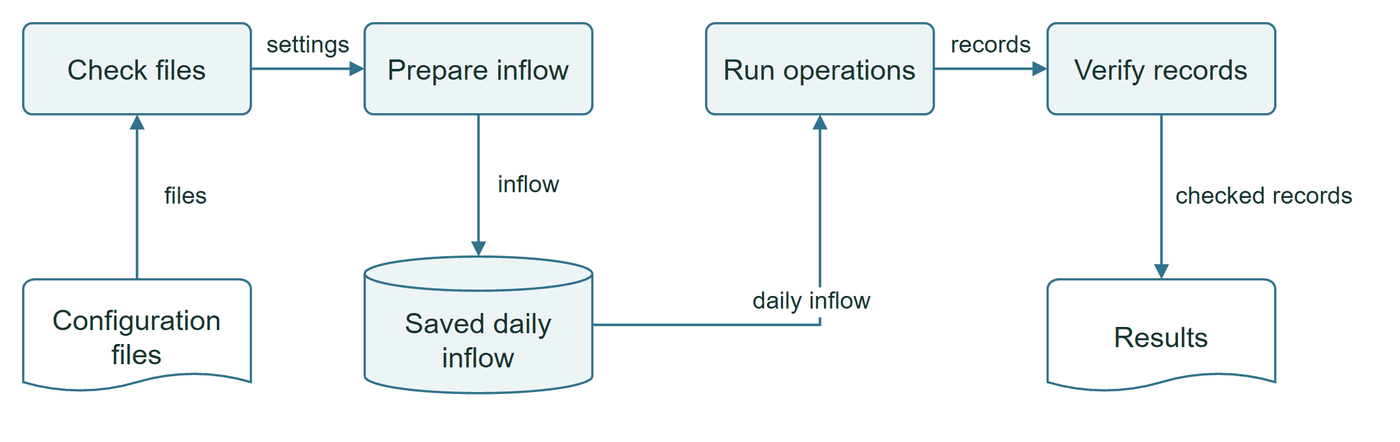

| Stage | Purpose |
| --- | --- |
| Check & Prepare | Validate limits, routing, dates, inflows ([guide](../docs/RUNNING.md)) |
| Run & Verify | Run 365 days in temp dir (`0` repo `runs/`), verify water balance |

In [3]:
from shutil import copytree
from tempfile import TemporaryDirectory, mkdtemp

import yaml

from llm_reservoir_agent.extensions import load_extension
from llm_reservoir_agent.verification import verify_run
from llm_reservoir_agent.workflow import run_settings

root = repo_root
example_dir = study_dir
if not (example_dir / "rule_based.yaml").is_file():
    raise FileNotFoundError("Open the notebook from the HydroReOpLLM checkout or its tutorials directory.")

config_paths = {
    "Rule-based": example_dir / "rule_based.yaml",
    "Without operational knowledge": example_dir / "seasonal_target.yaml",
    "With operational knowledge": example_dir / "dkp.yaml",
}


def run_case(name, *, allow_network=False, start_date=None, end_date=None, seed=None):
    run_root = Path(mkdtemp(prefix="hydroreopllm-walter-"))
    case_copy = run_root / "examples" / "fe_walter"
    copytree(example_dir, case_copy)
    config_file = case_copy / config_paths[name].name
    if allow_network or start_date is not None or end_date is not None or seed is not None:
        config = yaml.safe_load(config_file.read_text(encoding="utf-8"))
        if start_date is not None:
            config["start_date"] = start_date
        if end_date is not None:
            config["end_date"] = end_date
        s_day = pd.Timestamp(config["start_date"])
        e_day = pd.Timestamp(config["end_date"])
        n_days = (e_day - s_day).days + 1
        if allow_network:
            config["models"]["local"]["base_url"] = f"http://127.0.0.1:{OLLAMA_PORT}"
            if seed is not None:
                config["models"]["local"]["seed"] = seed
            config["max_calls"] = max(int(config.get("max_calls", 0)), 2 * n_days)
        config_file.write_text(yaml.safe_dump(config, sort_keys=False), encoding="utf-8")
    settings = load_settings(config_file)
    output = Path(settings.report["output"])
    run_settings(settings, allow_network=allow_network)
    verification = verify_run(output, require_offline=not allow_network)
    trajectory = pd.read_csv(output / "reservoir_trajectory.csv", parse_dates=["date"])
    print(f"{name}: {len(trajectory)} simulated days verified.")
    return {"trajectory": trajectory, "verification": verification, "output": output}


def verify_study_model(port):
    study, _ = load_extension("study/__init__.py", base_path=example_dir)
    study.verify_serving(f"http://127.0.0.1:{port}")

In [4]:
baseline = run_case("Rule-based", end_date="2021-12-31")
proof = baseline["verification"]
storage_diff = (baseline["trajectory"]["storage_end_m3"] - reference_runs["Rule-based"]["trajectory"]["storage_end_m3"]).abs().max()
print(f"Verification {proof['status']} | {proof['days']} days | {proof['observed_network_calls']} network calls")
print(f"Maximum water balance residual: {proof['max_system_balance_residual_m3']:.3g} m³ | Replay parity diff: {storage_diff:.3g} m³")

monthly = (
    baseline["trajectory"]
    .assign(Month=lambda df: df["date"].dt.strftime("%Y-%m"))
    .groupby("Month", as_index=False)
    .agg(
        inflow_cms=("inflow_cms", "mean"),
        target_release_cms=("target_release_cms", "mean"),
        controlled_release_cms=("controlled_release_cms", "mean"),
        spill_cms=("spill_cms", "mean"),
        storage_end_mm3=("storage_end_m3", lambda s: s.iloc[-1] / 1_000_000),
    )
    .rename(columns={
        "inflow_cms": "Mean inflow (m³/s)",
        "target_release_cms": "Mean requested (m³/s)",
        "controlled_release_cms": "Mean implemented (m³/s)",
        "spill_cms": "Mean spill (m³/s)",
        "storage_end_mm3": "Month-end storage (Mm³)",
    })
)
monthly.set_index("Month").round(2)

Rule-based: 365 simulated days verified.
Verification PASS | 365 days | 0 network calls
Maximum water balance residual: 9.13e-08 m³ | Replay parity diff: 1.49e-08 m³


,Mean inflow (m³/s),Mean requested (m³/s),Mean implemented (m³/s),Mean spill (m³/s),Month-end storage (Mm³)
Month,,,,,
2021-01,7.33,3.14,3.14,0.0,15.51
2021-02,8.10,6.45,6.45,0.0,19.49
2021-03,40.55,31.71,31.71,0.0,43.17
2021-04,11.28,8.93,8.93,0.0,49.26
2021-05,17.56,13.81,13.81,0.0,59.28
2021-06,7.55,6.02,6.02,0.0,63.23
2021-07,6.42,5.15,5.15,0.0,66.64
2021-08,28.11,22.03,22.03,0.0,82.93
2021-09,46.14,36.06,36.06,0.0,109.05


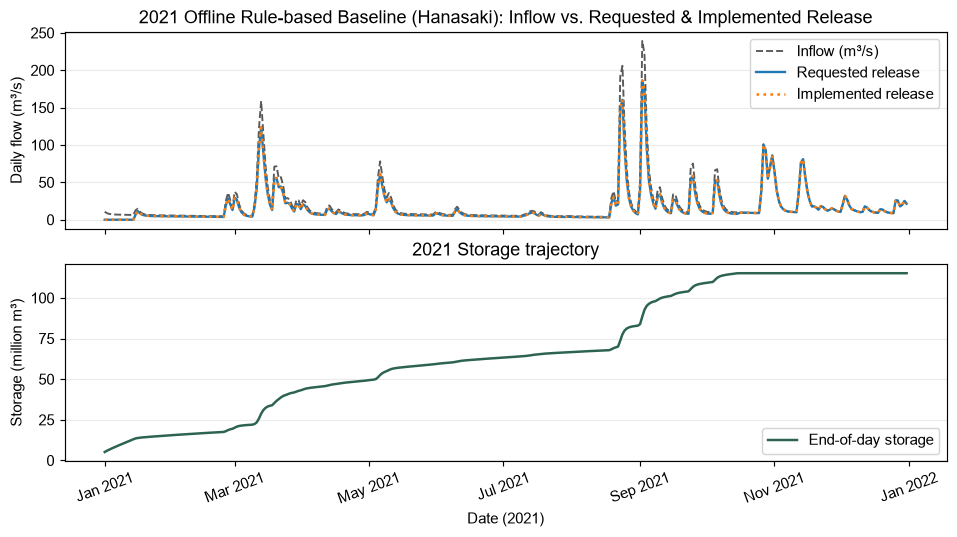

In [5]:
def plot_detailed_trajectory(trajectory, title):
    fig, (ax_flow, ax_storage) = plt.subplots(2, 1, sharex=True, figsize=(9.0, 5.0), dpi=105, layout="constrained")
    ax_flow.plot(trajectory["date"], trajectory["inflow_cms"], color="0.35", linestyle="--", linewidth=1.3, label="Inflow (m³/s)")
    ax_flow.plot(trajectory["date"], trajectory["target_release_cms"], color="#1f77b4", linestyle="-", linewidth=1.6, label="Requested release")
    ax_flow.plot(trajectory["date"], trajectory["controlled_release_cms"], color="#ff7f0e", linestyle=":", linewidth=1.8, label="Implemented release")
    if (trajectory["spill_cms"] > 0).any():
        ax_flow.plot(trajectory["date"], trajectory["spill_cms"], color="#d62728", linestyle="-.", linewidth=1.3, label="Spill")
    ax_flow.set(ylabel="Daily flow (m³/s)", title=f"{title}: Inflow vs. Requested & Implemented Release")
    ax_flow.legend(loc="upper right", frameon=True)
    ax_flow.grid(axis="y", alpha=0.25)

    ax_storage.plot(trajectory["date"], trajectory["storage_end_m3"] / 1_000_000, color="#2d6352", linewidth=1.7, label="End-of-day storage")
    ax_storage.set(ylabel="Storage (million m³)", xlabel="Date (2021)", title="2021 Storage trajectory")
    ax_storage.legend(loc="lower right", frameon=True)
    ax_storage.grid(axis="y", alpha=0.25)
    ax_storage.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax_storage.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax_storage.tick_params(axis="x", labelrotation=20)
    return fig

baseline_figure = plot_detailed_trajectory(baseline["trajectory"], "2021 Offline Rule-based Baseline (Hanasaki)")
plt.show()

### Output Files

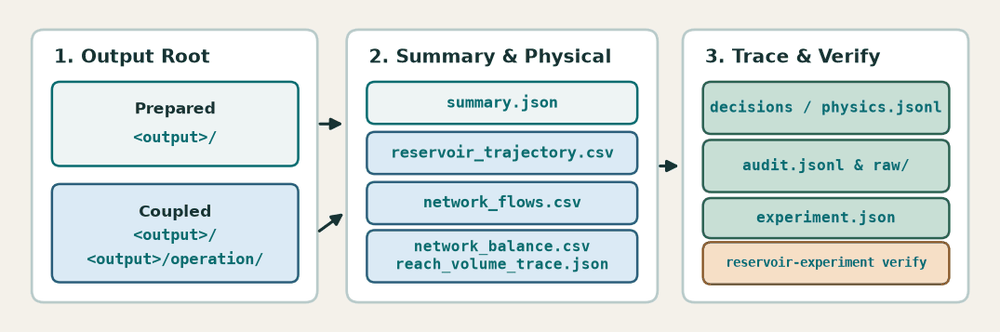

| File | Meaning |
| --- | --- |
| `reservoir_trajectory.csv` | Requested, implemented release, spill, and storage |
| `decisions/physics/audit.jsonl` | Step provenance & checks ([results guide](../docs/RESULTS_GUIDE.md)) |

## 5. Designing an LLM Operator

Four YAML blocks govern model choices, prompts, and safeguards:

| Block | Settings | Role |
| --- | --- | --- |
| `models` | `provider`, `model`, `temperature`, `seed`, `num_ctx`, `api_key_env` | Pins LLM & sampling |
| `prompt` | `$observation`, `$previous_transition`, `$knowledge`, `$information` | State, manual, forecasts ([info](../docs/INFORMATION.md)) |
| JSON reply | `reservoir-action.v1` / `study/response_schemas.json` | Structured release output |
| Safeguards | `--allow-network`, `max_calls`, `live_readiness`, `auditors` | Bounds, caps, zero-cost Day-1 preview |

In [6]:
check_results = {name: load_settings(path).report for name, path in config_paths.items()}
comparison = {}
for name in ("Without operational knowledge", "With operational knowledge"):
    config = yaml.safe_load(config_paths[name].read_text(encoding="utf-8"))
    method = config["agents"]["walter_operator"]["study_method"]
    comparison[name] = {
        "System prompt": f"prompts/{method}.system.txt",
        "First daily message": f"prompts/{method}.user.txt",
        "Operating guidance": "dkp.md" if method == "dkp" else "",
        "Planned decisions": check_results[name]["planned_llm_calls"],
        "max_calls": check_results[name]["max_calls"],
        "live_ready": check_results[name]["live_ready"],
        "Network calls during check": check_results[name]["network_calls"],
    }

pd.DataFrame.from_dict(comparison, orient="index")

,System prompt,First daily message,Operating guidance,Planned decisions,max_calls,live_ready,Network calls during check
Without operational knowledge,prompts/seasonal_target.system.txt,prompts/seasonal_target.user.txt,,7,14,True,0
With operational knowledge,prompts/dkp.system.txt,prompts/dkp.user.txt,dkp.md,7,14,True,0


In [7]:
# 1. Inspect F.E. Walter Day-1 system preview (0 network calls) and Day-1 user message
for label in ("Without operational knowledge", "With operational knowledge"):
    preview = check_results[label]["prompt_previews"]["walter_operator"]
    user_file = example_dir / comparison[label]["First daily message"]
    print(f"=== {label} (model_used={preview['model_used']}) ===")
    print("[System excerpt]:", preview["messages"][0]["content"][:200].replace("\n", " "), "...")
    print("[Day-1 user excerpt]:", user_file.read_text(encoding="utf-8")[:220].replace("\n", " "), "...\n")

# 2. Preview Day-1 prompt for a standard reservoir-action.v1 LLM operator (examples/multi_reservoir/hybrid_llm.yaml)
multi_llm_report = load_settings(root / "examples" / "multi_reservoir" / "hybrid_llm.yaml").report
multi_llm_preview = multi_llm_report["prompt_previews"]["lower_operator"]

print("=== Multi-Reservoir Hybrid LLM Day-1 Prompt Preview (reservoir-action.v1) ===")
print("Planned LLM calls:", multi_llm_report["planned_llm_calls"], "| Network calls:", multi_llm_report["network_calls"])
print(multi_llm_preview["messages"][0]["content"])

=== Without operational knowledge (model_used=False) ===
[System excerpt]: You are the operator of a reservoir, making one release decision per day.  Reservoir information (public sources): - Name: F.E. Walter Dam on the Lehigh River, Pennsylvania - Location: Bear Creek Town ...
[Day-1 user excerpt]: Date: 2021-01-01 (January, day 1 of the year) 1. Today's inflow: 376.8 cfs (= 32,556,387 cubic feet (= 747 acre-feet) over 1 days) 2. Water level at beginning of interval: 1312.72 ft NGVD29 3. Previous simulated release  ...

=== With operational knowledge (model_used=False) ===
[System excerpt]: You are the water control manager operating F.E. Walter Dam on the Lehigh River, Pennsylvania, making one release decision per day.  Reservoir information (public sources): - Name: F.E. Walter Dam on  ...
[Day-1 user excerpt]: Date: 2021-01-01 (January, day 1 of the year) 1. Today's inflow: 376.8 cfs (= 32,556,387 cubic feet (= 747 acre-feet) over 1 days) 2. Water level at beginning of interval: 1

## 6. Combining Rule-Based (Hanasaki) + LLM

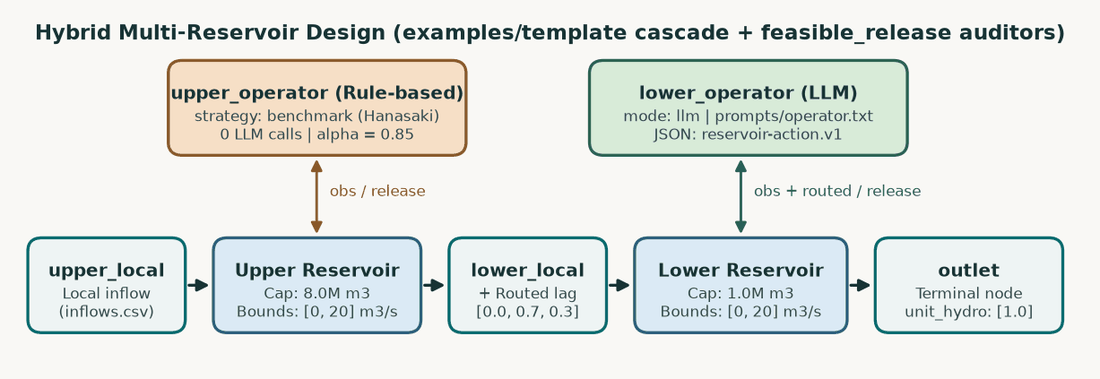

| Config | Upper (`upper`) | Lower (`lower`) | Role |
| --- | --- | --- | --- |
| `examples/multi_reservoir/hybrid_llm.yaml` | Hanasaki (`0` calls) | `mode: llm` (`prompts/operator.txt`) | Upstream rule routed with `[0.0, 0.7, 0.3]` lag (`max_calls: 10`) |
| `examples/multi_reservoir/rule_based.yaml` | Hanasaki (`0` calls) | Hanasaki (`0` calls) | Offline two-dam cascade verification baseline |

In [8]:
hybrid_report = load_settings(root / "examples" / "multi_reservoir" / "hybrid_llm.yaml").report

print("Hybrid config (examples/multi_reservoir/hybrid_llm.yaml):")
print("  Agent types:", hybrid_report["agent_types"], "| Rules:", hybrid_report["agent_rules"])
print(f"  Days: {hybrid_report['days']} | Planned LLM calls: {hybrid_report['planned_llm_calls']} | Network calls: {hybrid_report['network_calls']}")

with TemporaryDirectory(prefix="hydroreopllm-multi-") as tmp_dir:
    multi_stage = Path(tmp_dir) / "examples" / "multi_reservoir"
    copytree(root / "examples" / "multi_reservoir", multi_stage)
    multi_rule_settings = load_settings(multi_stage / "rule_based.yaml")
    multi_rule_output = Path(multi_rule_settings.report["output"])
    run_settings(multi_rule_settings, allow_network=False)
    multi_rule_verification = verify_run(multi_rule_output, require_offline=True)
    multi_rule_trajectory = pd.read_csv(multi_rule_output / "reservoir_trajectory.csv", parse_dates=["date"])

final_storages = (
    multi_rule_trajectory.groupby("reservoir_id")["storage_end_m3"]
    .last()
    .round(0)
    .astype(int)
    .to_dict()
)
print(
    f"Offline cascade (examples/multi_reservoir/rule_based.yaml): "
    f"Verification {multi_rule_verification['status']} | {multi_rule_verification['days']} days | "
    f"{multi_rule_verification['observed_network_calls']} network calls | "
    f"residual={multi_rule_verification['max_system_balance_residual_m3']:.3g} m³"
)
print("  Final storages (m³):", final_storages)

Hybrid config (examples/multi_reservoir/hybrid_llm.yaml):
  Agent types: {'upper_operator': 'rule_based', 'lower_operator': 'llm'} | Rules: {'upper_operator': 'hanasaki'}
  Days: 10 | Planned LLM calls: 10 | Network calls: 0


Offline cascade (examples/multi_reservoir/rule_based.yaml): Verification PASS | 10 days | 0 network calls | residual=6.98e-10 m³
  Final storages (m³): {'lower': 800044, 'upper': 3023037}


## 7. Live Ollama Inference (2021, Optional)

| Step | Action |
| --- | --- |
| 1 | Start Ollama 0.40.6 + `gemma4:12b` ([study guide](../examples/fe_walter/README.md)) |
| 2 | Set `RUN_LLM = True` (`LLM_END_DATE = "2021-12-31"` or `"2021-01-07"`) |
| 3 | Inspect outputs ([results guide](../docs/RESULTS_GUIDE.md)) |

In [9]:
RUN_LLM = False
OLLAMA_PORT = 11434
LLM_START_DATE = "2021-01-01"
LLM_END_DATE = "2021-12-31"
LLM_SEED = 3

In [10]:
llm_runs = {}
if RUN_LLM:
    verify_study_model(OLLAMA_PORT)
    obs_window = obs_2021[(obs_2021["date"] >= LLM_START_DATE) & (obs_2021["date"] <= LLM_END_DATE)]
    live_metrics = []
    for name in comparison:
        llm_runs[name] = run_case(
            name,
            allow_network=True,
            start_date=LLM_START_DATE,
            end_date=LLM_END_DATE,
            seed=LLM_SEED,
        )
        verification = llm_runs[name]["verification"]
        print(f"Verification {verification['status']} | {verification['days']} days | {verification['observed_network_calls']} network calls")
        traj = llm_runs[name]["trajectory"]
        if len(traj) >= 2:
            e_score = score_series(storage_to_elevation_ft(traj["storage_end_m3"]), obs_window["water_level_ft"])
            r_score = score_series(traj["total_outflow_cms"] / CFS_TO_CMS, obs_window["release_cfs"])
            live_metrics.append({
                "Case": name,
                "Elev KGE": e_score["kge"],
                "Elev RMSE (ft)": e_score["rmse"],
                "Release KGE": r_score["kge"],
                "Release RMSE (ft³/s)": r_score["rmse"],
            })
    if live_metrics:
        print(pd.DataFrame(live_metrics).set_index("Case").round(3).to_string())
    rule_slice = baseline["trajectory"]
    rule_slice = rule_slice[(rule_slice["date"] >= LLM_START_DATE) & (rule_slice["date"] <= LLM_END_DATE)].reset_index(drop=True)
    comparison_figure = plot_figure3_2021({"Rule-based": {"trajectory": rule_slice}, **llm_runs})
    plt.show()
else:
    print("Run All completed the 2021 offline replay (Paper Fig. 3), 365-day baseline, prompt previews, and hybrid check. Enable RUN_LLM above to run live Ollama.")

Run All completed the 2021 offline replay (Paper Fig. 3), 365-day baseline, prompt previews, and hybrid check. Enable RUN_LLM above to run live Ollama.
